# MECHA in metafspm, 3: a pine needle, its sections joined, its water and its sugars over a day

The reactions branch of MECHA (`legacy_reactions`) simulates sucrose and starch in one pine needle cross section:
photosynthesis in the mesophyll, transport by diffusion and with the water through walls, membranes and
plasmodesmata, loading into the phloem, starch in the cells, and the sugars' osmotic effect on the water. Its port,
`MechaSolutes`, reproduces it exactly on the same section (`MECHA-dev/test/comparison/test_solutes.py`,
`example/comparison/compare_solutes*.py`).

This tutorial does it in metafspm, on a needle **organ**:

1. the needle as an organ of three segments (`SubOrgan` leaf elements), each with GRANAP's needle anatomy, the
   sections joined by their xylem and phloem;
2. its water: the twig's potential at the base, the **organ's transpiration** (an `Organ`-scale input) leaving
   through the stomata of all its sections;
3. its sugars, coupled to the water both ways (the water's flows carry the sucrose; the sucrose's osmotic potential
   drives the water), over a day of light.

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.metafspm.coupling.choregrapher import Choregrapher
from openalea.metafspm.coupling.component import StructuralComponent
from openalea.metafspm.data_structure.configs import PropsConfig
from openalea.metafspm.data_structure.data_api import MPGDataStructure
from openalea.metafspm.scene.population import build_population

from openalea.granap.metafspm.component import GranapAnatomy, OrganAnatomy, junction_rules
from openalea.granap.metafspm.library import AnatomyLibrary, preset_parameters
from openalea.granap.needle_class import NeedleAnatomy
from openalea.mecha.component import MechaHydraulics
from openalea.mecha.osmotic import MechaOsmoticPresets
from openalea.mecha.solutes import MechaSolutes

DT = 3600.                                              # s: one hour per step
Choregrapher().add_simulation_time_step(DT)

## 1. The needle: an organ of three sections

The architecture: a shoot axis whose leaf organ (`Organ`, label `Leaf`) has three leaf elements (`SubOrgan`,
`LeafElement`), base to tip, joined by `<` edges (each the successor of the previous). GRANAP's component gets a
library for leaf elements: the needle preset (`NeedleAnatomy`, seed 42: the reactions branch's section), one class
(`size=None`). The three sections are three copies of one template; `junction_rules` joins their conducting cells
(xylem to xylem, phloem to phloem) between successive sections.

In [2]:
N_SECTIONS, SECTION_LENGTH, NEEDLE_RADIUS = 3, 2e-3, 0.6e-3        # m


class Needle(StructuralComponent):
    @classmethod
    def initiate_plant(cls, g, plant, parameters):
        s, L = g.scales, g.labels
        complex_ = plant
        for scale, label in ((s.Axis, L.Axis.Shoot), (s.GrowthUnit, L.GrowthUnit.Shoot),
                             (s.Phytomer, L.Phytomer.Shoot), (s.Organ, L.Organ.Leaf)):
            complex_ = g.add_component(complex_, **PropsConfig(scale=scale, edge_type='/', label=label))
        element = None
        for rank in range(N_SECTIONS):
            props = PropsConfig(scale=s.SubOrgan, edge_type='<' if element else '/', label=L.SubOrgan.LeafElement)
            element = g.add_child(element, **props) if element else g.add_component(complex_, **props)
            g.property("radius")[element], g.property("length")[element] = NEEDLE_RADIUS, SECTION_LENGTH
            g.property("distance_from_tip")[element] = (N_SECTIONS - 1 - rank) * SECTION_LENGTH


class NeedleSections(GranapAnatomy):
    shoot = {"LeafElement": OrganAnatomy(AnatomyLibrary(parameters=preset_parameters("for_needle"),
                                                        organ_class=NeedleAnatomy, seed=42), size=None)}


plants = pd.DataFrame([dict(plant="pine", model=None, x=0., y=0., z=0., rotation=0., scenario={"parameters": {}})])
g, _ = build_population(plants, initiators=(Needle, NeedleSections))
g.convert_properties_to_arraydict()
ds = MPGDataStructure(g, from_scale=g.scales.SubOrgan, nodes="Compartment", wiring=junction_rules(g))
anatomy = NeedleSections(data_structure=ds)
anatomy()

sections = [int(v) for v in ds.entity_ids("SubOrgan")]
owner = ds.owner("SubOrgan")
path, kind = np.asarray(ds.get("network_path")), np.asarray(ds.get("kind"))
view = ds.to_graph_view()
print(f"{len(sections)} sections, {len(NeedleSections.shoot['LeafElement'].library.templates)} template; "
      f"{ds.n_nodes()} Compartments, {ds.n_edges()} Connections")
print(f"axial junctions between successive sections: {int((path == 5).sum())}; "
      f"the leaf organ's surface: {int((kind == 3).sum())} Compartment (kind 3), "
      f"{int((path == 6).sum())} stomatal Connections from the pores of all three sections")

3 sections, 1 template; 48586 Compartments, 118963 Connections
axial junctions between successive sections: 1420; the leaf organ's surface: 1 Compartment (kind 3), 12 stomatal Connections from the pores of all three sections


## 2. The organ's transpiration, an `Organ`-scale input

A transpiration (or stomatal) model computes one value per leaf organ: `leaf_transpiration` (cm³ d⁻¹, role
`Transpiration`), declared by MECHA at the `Organ` scale. The DataStructure stores it per `Organ` entity; MECHA maps
it down to the organ's surface Compartment (`ds.owner("Organ")` gives each Compartment's organ), where it is a
Neumann boundary (`surface_inflow` = −transpiration). The stomatal Connections join every pore of the organ's
sections to that surface: the water leaves through them, each pore's share set by its vapour conductance (its
aperture `stomatal_aperture`, role `Stomata`, 1 here).

An `Organ`-scale input is read from the MTG property when the component registers its inputs, so it is set on the
organ before the component is built; afterwards it is a DataStructure variable like any other (`ds.set`).

In [3]:
E_MAX = 0.03                                            # cm3 d-1: the needle's transpiration at noon
organs = [int(v) for v in ds.entity_ids("Organ")]
leaves = [v for v in organs if g.property("label").get(v) == g.labels.Organ.Leaf]
for v in organs:
    g.property("leaf_transpiration")[v] = E_MAX if v in leaves else 0.

ds.register("barrier", np.ones(ds.n_nodes()), location="node")       # mature xylem in every section

presets = MechaOsmoticPresets(data_structure=ds)       # the osmotic baseline ("Solutes" role)
presets.presets_sections, presets.s_factor = 2., 0.7    # on every section, σ 0.7: the reactions' needle

mecha = MechaHydraulics(data_structure=ds)
for name, value in dict(kw=2.5634e-3, kw_meso_hypo=1e-16, kmb=3.6314e-4).items():   # the needle's (InData)
    setattr(mecha, name, value)
mecha.collar_condition, mecha.collar_psi = 1., -5000.   # the twig's xylem at -0.5 MPa, at the base section
mecha.standard_solve = 0.                               # the plant problem only

presets()
mecha()
surface = np.flatnonzero(kind == 3)
stomatal = np.flatnonzero(path == 6)
evaporation = np.asarray(ds.get("evaporation"))
print("leaf_transpiration per Organ (cm³ d⁻¹):",
      {int(v): float(e) for v, e in zip(organs, ds.get("leaf_transpiration"))})
print(f"surface node's boundary inflow {float(ds.get('surface_inflow')[surface[0]]):.4f} cm³ d⁻¹; "
      f"flow through the {stomatal.size} stomatal Connections {float(ds.get('flow')[stomatal].sum()):.4f}; "
      f"evaporated by the pores of each section: "
      + ", ".join(f"{evaporation[owner == i].sum():.4f}" for i in range(len(sections))))

leaf_transpiration per Organ (cm³ d⁻¹): {15: 0.03}
surface node's boundary inflow -0.0300 cm³ d⁻¹; flow through the 12 stomatal Connections 0.0300; evaporated by the pores of each section: 0.0100, 0.0100, 0.0100


Which way does the water go? The base section's xylem takes it from the twig; the xylem junctions carry it to the
other sections (they conduct far more than the radial path: the three sections evaporate alike); in each, it
crosses the bundle sheath, the transfusion tissue and the mesophyll to the sub-stomatal chambers and the pores.

Across a membrane, MECHA's flow is K (Δψ + σ Δπ), with σ = 0.7 here: neither the pressure ψ nor ψ + π alone gives
its direction. Per tissue, at noon: the walls are under tension, near the xylem's (the twig's −5000 hPa); the
living cells hold turgor (ψ > the walls') with the presets' π (−4800 hPa, the root cortex's, applied to the
needle as the reactions branch does); the phloem, with the sieve tubes' −10000 hPa, is turgid. The transfusion
cells (cgroup 17) get no π: MECHA's presets are root rules, with none for them.

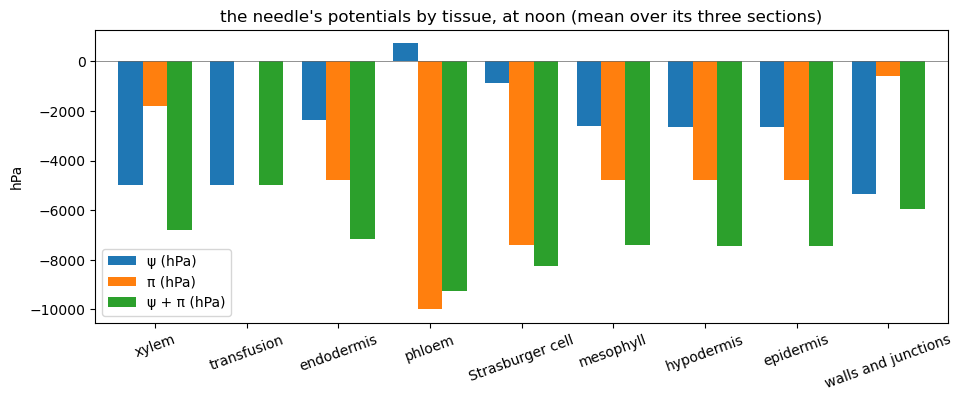

,Compartments,ψ (hPa),π (hPa),ψ + π (hPa)
,,,,
xylem,1182,-5000.0,-1800.0,-6800.0
transfusion,309,-4998.0,0.0,-4998.0
endodermis,147,-2371.0,-4800.0,-7171.0
phloem,948,723.0,-10000.0,-9277.0
Strasburger cell,213,-863.0,-7400.0,-8263.0
mesophyll,756,-2616.0,-4800.0,-7416.0
hypodermis,1158,-2627.0,-4800.0,-7427.0
epidermis,717,-2630.0,-4800.0,-7430.0
walls and junctions,40227,-5363.0,-593.0,-5956.0


In [4]:
psi, pi = np.asarray(ds.get("psi")), np.asarray(ds.get("osmotic_potential"))
liquid = np.asarray(ds.get("vapour_node")) == 0
tissue = np.asarray(ds.get("tissue"), dtype=object)
rows = [(name, int(m.sum()), psi[m].mean(), pi[m].mean()) for name in
        ("xylem", "transfusion", "endodermis", "phloem", "Strasburger cell", "mesophyll", "hypodermis", "epidermis")
        for m in [(kind == 0) & (tissue == name) & liquid] if m.any()]
walls = (kind > 0) & (kind < 3) & liquid
rows.append(("walls and junctions", int(walls.sum()), psi[walls].mean(), pi[walls].mean()))
table = pd.DataFrame(rows, columns=["", "Compartments", "ψ (hPa)", "π (hPa)"]).set_index("")
table["ψ + π (hPa)"] = table["ψ (hPa)"] + table["π (hPa)"]
fig, ax = plt.subplots(figsize=(11, 3.8))
table[["ψ (hPa)", "π (hPa)", "ψ + π (hPa)"]].plot.bar(ax=ax, width=0.8)
ax.axhline(0., color="0.4", lw=0.5)
ax.set(ylabel="hPa", title="the needle's potentials by tissue, at noon (mean over its three sections)")
plt.xticks(rotation=20)
plt.show()
table.round(0)

## 3. The sugars: `MechaSolutes` on the same DataStructure

`MechaSolutes` reads the water's `flow` (role `Hydraulics`), the diffusion factors and volumes MechaHydraulics
derives from the sections, the membranes' `reflection_coefficient`, and a photosynthetic source `sucrose_source`
(mol d⁻¹ per Compartment, role `Photosynthesis`). It solves sucrose and starch on the liquid nodes, one implicit
step per time step, and writes `sucrose_osmotic_potential` (−R T c on the cells), which the presets add to their
baseline: the next water solve sees it.

In each section, the sucrose moves radially (walls, membranes, plasmodesmata) to the sinks: the phloem-loading
Strasburger cells and the xylem, at `c_sink`. Its transport along the needle in the phloem is not modelled (as in
the reactions branch): each section loads its own.

In [5]:
solutes = MechaSolutes(data_structure=ds, time_step=DT)
solutes.k_starch_synthesis, solutes.k_starch_degradation = 2.0, 1.0   # d-1, the reactions' diurnal runs
mesophyll = (kind == 0) & (tissue == "mesophyll") & liquid
volume = lambda: np.asarray(ds.get("node_volume"))                    # cm3, MechaHydraulics'
C_PHOTO = 5e-6                                                        # mol cm-3 per hour at full light


def light(hour):
    return max(0., np.sin(np.pi * (hour - 6.) / 12.))                 # 6 h to 18 h


def step(hour):
    """One hour: the organ's transpiration and the mesophyll's photosynthesis follow the light; then the osmotic
    baseline with the sucrose's π, the water, and the sugars on the water's flows."""
    ds.set("leaf_transpiration", np.where(np.isin(organs, leaves), E_MAX * max(light(hour), 0.05), 0.))
    ds.set("sucrose_source", np.where(mesophyll, volume() * C_PHOTO * light(hour) / (DT / 86400.), 0.))
    presets()
    mecha()
    solutes()


history = []
for hour in range(24):
    step(hour + 0.5)
    c, s, V = np.asarray(ds.get("sucrose")), np.asarray(ds.get("starch")), volume()
    sink = np.asarray(ds.get("sucrose_sink")) > 0
    held = (np.asarray(ds.get("liquid_node")) > 0) & ~sink
    history.append(dict(hour=hour + 1, light=light(hour + 0.5),
                        transpiration=float(ds.get("evaporation").sum()),
                        mesophyll_psi=float(np.asarray(ds.get("water_potential"))[mesophyll].mean()),
                        mesophyll_pi=float(np.asarray(ds.get("osmotic_potential"))[mesophyll].mean()),
                        sucrose_cells=float((c * V)[held & (kind == 0)].sum()),
                        sucrose_walls=float((c * V)[held & (kind > 0)].sum()),
                        starch=float((s * V)[held].sum()),
                        produced=float(ds.get("sucrose_source").sum()) * DT / 86400.))
    if hour + 1 == 12:
        noon = dict(c=c.copy(), psi=np.asarray(ds.get("water_potential")).copy())
day = pd.DataFrame(history).set_index("hour")
day["produced"] = day["produced"].cumsum()
day["taken by the sinks"] = day["produced"] - day[["sucrose_cells", "sucrose_walls", "starch"]].sum(axis=1)
day.round(9)

,light,transpiration,mesophyll_psi,mesophyll_pi,sucrose_cells,sucrose_walls,starch,produced,taken by the sinks
hour,,,,,,,,,
1,0.000000,0.001500,-6922.276469,-4800.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
2,0.000000,0.001500,-6922.276469,-4800.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
3,0.000000,0.001500,-6922.276469,-4800.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
4,0.000000,0.001500,-6922.276469,-4800.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
5,0.000000,0.001500,-6922.276469,-4800.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
6,0.000000,0.001500,-6922.276469,-4800.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
7,0.130526,0.003916,-6964.104775,-4800.000000,3.000000e-09,0.000000e+00,0.000000e+00,3.000000e-09,0.000000e+00
8,0.382683,0.011481,-7098.314764,-4810.022702,1.000000e-08,0.000000e+00,1.000000e-09,1.100000e-08,1.000000e-09
9,0.608761,0.018263,-7224.459912,-4837.113980,2.000000e-08,1.000000e-09,3.000000e-09,2.500000e-08,1.000000e-09


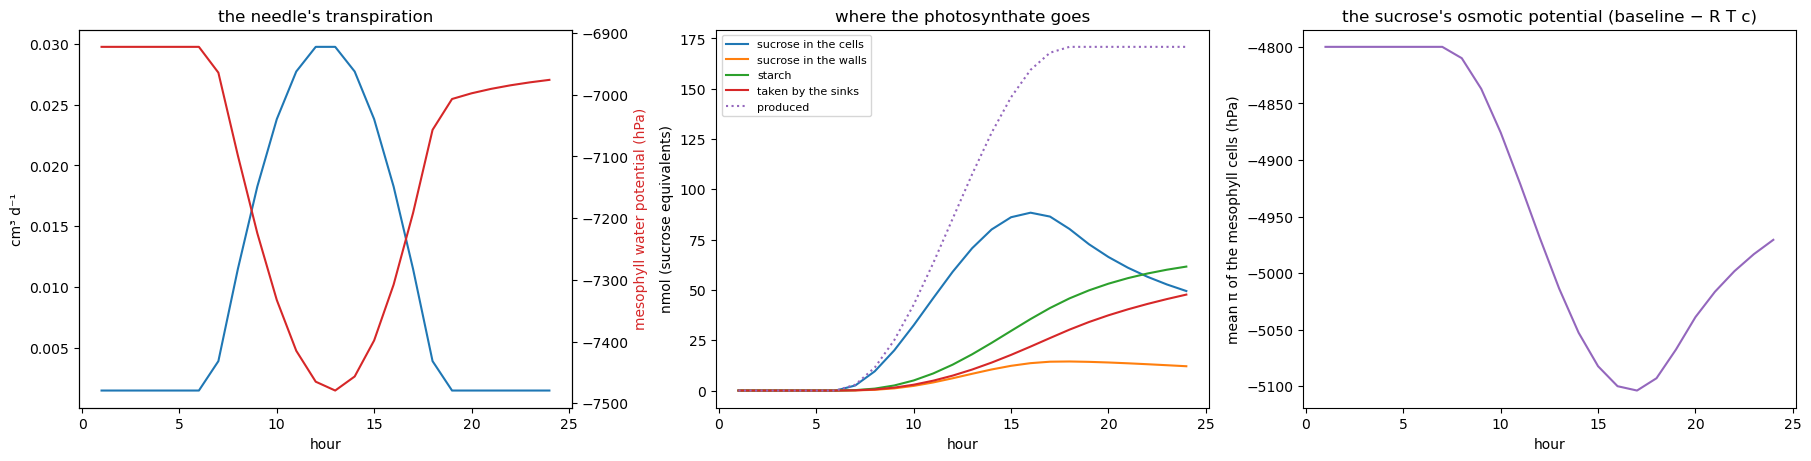

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), layout="constrained")
axes[0].plot(day.index, day["transpiration"], label="transpiration (cm³ d⁻¹)")
axes[0].set(xlabel="hour", ylabel="cm³ d⁻¹", title="the needle's transpiration")
ax = axes[0].twinx()
ax.plot(day.index, day["mesophyll_psi"], color="tab:red", label="mesophyll ψ + π")
ax.set_ylabel("mesophyll water potential (hPa)", color="tab:red")
for name in ("sucrose_cells", "sucrose_walls", "starch", "taken by the sinks", "produced"):
    axes[1].plot(day.index, day[name] * 1e9, ":" if name == "produced" else "-", label=name.replace("_", " in the "))
axes[1].set(xlabel="hour", ylabel="nmol (sucrose equivalents)", title="where the photosynthate goes")
axes[1].legend(fontsize=8)
axes[2].plot(day.index, day["mesophyll_pi"], color="tab:purple")
axes[2].set(xlabel="hour", ylabel="mean π of the mesophyll cells (hPa)",
            title="the sucrose's osmotic potential (baseline − R T c)")
plt.show()

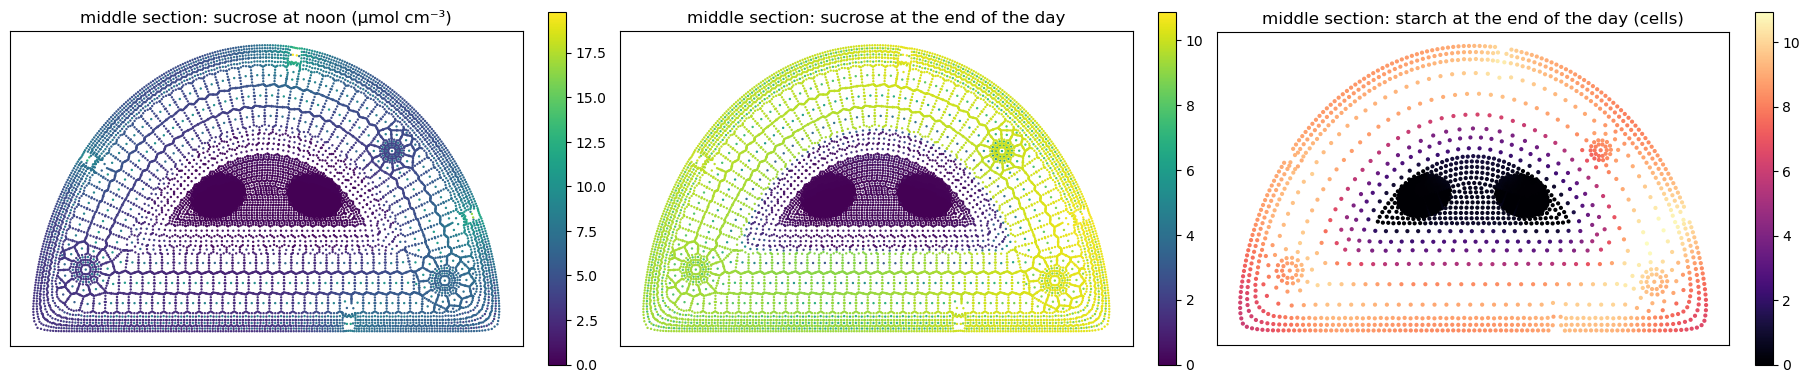

In [7]:
x, y = np.asarray(ds.get("section_x")), np.asarray(ds.get("section_y"))       # mm, in each section
c_end = np.asarray(ds.get("sucrose"))
starch_end = np.asarray(ds.get("starch"))
fig, axes = plt.subplots(1, 3, figsize=(18, 4), layout="constrained")
i = 1                                                                 # the middle section
nodes = (owner == i) & liquid
for ax, values, title, cmap, where in ((axes[0], noon["c"], "sucrose at noon (µmol cm⁻³)", "viridis", nodes),
                                       (axes[1], c_end, "sucrose at the end of the day", "viridis", nodes),
                                       (axes[2], starch_end, "starch at the end of the day (cells)", "magma",
                                        nodes & (kind == 0))):
    points = ax.scatter(x[where], y[where], c=values[where] * 1e6, s=0.5 if where is nodes else 4, cmap=cmap)
    fig.colorbar(points, ax=ax, shrink=0.9)
    ax.set(aspect="equal", title=f"middle section: {title}")
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

## What to take away

- An organ's sections are joined by the DataStructure (`junction_rules`); MECHA solves them as one plant problem,
  the organ's transpiration entering as an `Organ`-scale input mapped onto its surface node and its stomata.
- The solutes are a second component on the same DataStructure: the hydraulics' outputs are its inputs, its
  osmotic potential the presets' input, the presets' output the hydraulics' input. Each component is called once
  per step, in that order; no component imports another.
- The reactions branch's problems not ported (its osmotic flow counted twice, its starch in the walls, its sugars on
  the vapour path) are measured in `devplan_metafspm.md` §28e and `example/comparison/compare_solutes.py`.
- Next: `tutorial_metafspm_04_full_plant.ipynb`, a whole plant in its soil.